# MFACT: `coverage` × 11 Variabel (Multiple Factor Analysis for Contingency Tables)

**Gagasan:** 11 tabel kontingensi `coverage` × variabel-lain ditempel berdampingan menjadi satu tabel besar **3 × 47** (3 baris = Basic/Extended/Premium, 47 kolom = semua kategori dari 11 variabel). Tiap variabel disebut satu **grup**.
"Tabel" di sini adalah **tabel frekuensi (kontingensi)**, bukan tabel koordinat. Koordinat baru muncul di Langkah 5.

Urutan notebook:

| Langkah | Isi |
|---|---|
| 1 | Tabel kontingensi gabungan (3 × 47) |
| 2 | Matriks proporsi P, massa baris global, massa kolom |
| 3 | Analisis **pseudo-terpisah** tiap tabel → λ₁ᵗ |
| 4 | Pembobotan 1/λ₁ᵗ, SVD global, nilai eigen |
| 5 | Koordinat baris dan kolom |
| 6 | Kontribusi kolom dan **grup** |
| 7 | Sumbu parsial (korelasi dimensi global vs dimensi tiap tabel) |
| 8 | Peta: simetris, asimetris baris, grup, sumbu parsial, superposisi |
| 9 | Uji sensitivitas: 11 variabel vs tanpa variabel terlemah vs tanpa variabel "nilai" |
| 10 | Ekspor koordinat kolom untuk klasterisasi |

Semua perhitungan inti ada di fungsi `mfact_core()` (tiap langkah diberi komentar). Sel-sel langkah hanya menampilkan dan memeriksa hasilnya.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.float_format', lambda x: f'{x:.4f}')
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})

df = pd.read_csv('ibm_watson_coverage.csv')
ROW_VAR = 'coverage'
VARS_ALL = [c for c in df.columns if c != ROW_VAR]          # 11 variabel
SHORT = {'education':'edu','employment_status':'emp','region':'reg','renew_offer_type':'ren',
         'sales_channel':'sal','vehicle_class':'veh','income_cat':'inc','clv_cat':'clv',
         'monthly_premium_cat':'prm','total_claim_cat':'clm','tenure_cat':'ten'}
ORDER = {'coverage': ['Basic','Extended','Premium'],
         'education': ['High School or Below','College','Bachelor','Master','Doctor'],
         'income_cat': ['Nol (0)','Rendah','Menengah','Tinggi'],
         'tenure_cat': ['Baru','Menengah','Lama','Sangat Lama']}
def cats(var):
    present = set(df[var].unique())
    order = [c for c in ORDER.get(var, sorted(present)) if c in present]
    return order + sorted(present - set(order))
def shortcat(c): return str(c).split(' (')[0]
print(df.shape, '| 11 variabel:', VARS_ALL)

(9134, 12) | 11 variabel: ['education', 'employment_status', 'region', 'renew_offer_type', 'sales_channel', 'vehicle_class', 'income_cat', 'clv_cat', 'monthly_premium_cat', 'total_claim_cat', 'tenure_cat']


In [2]:
def corr_w(x, y, w):
    """Korelasi berbobot tanpa pemusatan ulang (sesuai Persamaan II.45; koordinat sudah terpusat oleh massa)."""
    return np.sum(w*x*y) / (np.sqrt(np.sum(w*x*x)) * np.sqrt(np.sum(w*y*y)))

def anchor_sign(F, rows, v):
    """Tanda sumbu ditetapkan agar Premium positif di Dim 1 dan Extended positif di Dim 2 (hanya kosmetik)."""
    s = np.ones(F.shape[1])
    if 'Premium'  in rows and F.shape[1] > 0: s[0] = 1 if F[rows.index('Premium'), 0]  >= 0 else -1
    if 'Extended' in rows and F.shape[1] > 1: s[1] = 1 if F[rows.index('Extended'), 1] >= 0 else -1
    return s

def mfact_core(vars_):
    # ---------- Langkah 1: tabel kontingensi gabungan ----------
    rows = cats(ROW_VAR)
    tabs = [pd.crosstab(df[ROW_VAR], df[v]).reindex(index=rows, columns=cats(v)) for v in vars_]
    Kt = pd.concat(tabs, axis=1, keys=vars_)                     # kolom: MultiIndex (grup, kategori)
    I, J, T = Kt.shape[0], Kt.shape[1], len(vars_)
    grp = np.array([g for g, _ in Kt.columns])
    # ---------- Langkah 2: proporsi, massa ----------
    Nmat = Kt.values.astype(float); ntot = Nmat.sum()
    P = Nmat / ntot                                              # jumlah seluruh sel = 1
    r = P.sum(axis=1)                                            # massa baris GLOBAL p_i..
    pc = P.sum(axis=0)                                           # massa kolom p_.jt
    # ---------- Langkah 3: analisis pseudo-terpisah per tabel ----------
    S_all = np.zeros_like(P); lam_t = {}; Fps = {}; sca_lam = {}; ps_info = []
    for v in vars_:
        m = grp == v; Pt = P[:, m]; pt = Pt.sum(); pit = Pt.sum(1); pjt = Pt.sum(0)
        E = np.outer(pit/pt, pjt)                                # ekspektasi memakai margin baris tabel itu sendiri
        St = (Pt - E) / np.sqrt(np.outer(r, pjt))                # residual terstandarisasi pseudo-terpisah
        S_all[:, m] = St
        U_, s_, Vt_ = np.linalg.svd(St, full_matrices=False)
        k = min(I-1, Pt.shape[1]-1); lam = s_[:k]**2
        Ft = (U_[:, :k] / np.sqrt(r)[:, None]) * s_[:k]          # koordinat utama baris pseudo-terpisah
        Ft = Ft * anchor_sign(Ft, rows, v)
        lam_t[v] = lam; Fps[v] = Ft
        # pembanding: SCA biasa (massa baris lokal) pada tabel yang sama
        Nt = Kt.loc[:, v].values.astype(float); Pl = Nt/Nt.sum(); rl, cl = Pl.sum(1), Pl.sum(0)
        Sl = (Pl - np.outer(rl, cl)) / np.sqrt(np.outer(rl, cl))
        sca_lam[v] = np.linalg.svd(Sl, compute_uv=False)[:k]**2
        ps_info.append(dict(grup=v, lambda1=lam[0], lambda2=lam[1] if k > 1 else 0.0,
                            lambda1_x_T=lam[0]*T, lambda1_SCA=sca_lam[v][0],
                            bobot_1_per_lambda1=1/lam[0]))
    ps = pd.DataFrame(ps_info).set_index('grup')
    # ---------- Langkah 4: pembobotan + SVD global ----------
    lam1_col = np.array([lam_t[g][0] for g in grp])              # lambda1 tabel pemilik kolom
    S_tilde = S_all / np.sqrt(lam1_col)                          # tiap kolom dibobot 1/lambda1^t (dalam akar)
    U, s, Vt = np.linalg.svd(S_tilde, full_matrices=False)
    K = min(I-1, J-1); U, s, V = U[:, :K], s[:K], Vt[:K].T
    lam = s**2; pct = lam/lam.sum()*100
    # ---------- Langkah 5: koordinat ----------
    Phi = U / np.sqrt(r)[:, None]; F = Phi * s                   # baris: standar, utama
    w = pc / lam1_col                                            # bobot kolom p_.jt / lambda1^t
    Gamma = V / np.sqrt(w)[:, None]; G = Gamma * s               # kolom: standar, utama
    sg = anchor_sign(F, rows, None)
    U, V, Phi, F, Gamma, G = U*sg, V*sg, Phi*sg, F*sg, Gamma*sg, G*sg
    # ---------- Langkah 6: kontribusi kolom dan grup ----------
    ctr_col = V**2                                               # = w_j G_js^2 / lambda_s
    cos2_col = G**2 / (G**2).sum(1, keepdims=True)
    in_col = w * (G**2).sum(1)
    GC = np.vstack([lam * (V[grp == v]**2).sum(0) for v in vars_])   # koordinat grup; jumlah per dimensi = lambda_s
    GCpct = GC / lam * 100
    # ---------- Langkah 7: sumbu parsial ----------
    pa = []
    for v in vars_:
        for u in range(Fps[v].shape[1]):
            pa.append(dict(grup=v, dim_tabel=u+1, **{f'korelasi Dim{d+1}': corr_w(F[:, d], Fps[v][:, u], r) for d in range(K)}))
    pa = pd.DataFrame(pa)
    pa['panjang vektor'] = np.sqrt((pa[[f'korelasi Dim{d+1}' for d in range(K)]]**2).sum(1))
    # ---------- koordinat parsial (superposisi) ----------
    Fpart = {}
    for v in vars_:
        m = grp == v; Pt = P[:, m]; E = np.outer(Pt.sum(1)/Pt.sum(), Pt.sum(0))
        Fpart[v] = T * ((Pt - E) / r[:, None]) @ Gamma[m] / lam_t[v][0]
    return dict(vars=vars_, rows=rows, Kt=Kt, I=I, J=J, T=T, grp=grp, ntot=ntot, P=P, r=r, pc=pc,
                ps=ps, lam_t=lam_t, Fps=Fps, S_all=S_all, lam1_col=lam1_col, S_tilde=S_tilde, U=U, s=s, V=V,
                K=K, lam=lam, pct=pct, Phi=Phi, F=F, w=w, Gamma=Gamma, G=G, ctr_col=ctr_col, cos2_col=cos2_col,
                in_col=in_col, GC=GC, GCpct=GCpct, pa=pa, Fpart=Fpart)

M = mfact_core(VARS_ALL)
print('Selesai: I =', M['I'], '| J =', M['J'], '| T =', M['T'], '| dimensi maks K =', M['K'])

Selesai: I = 3 | J = 47 | T = 11 | dimensi maks K = 2


## Langkah 1: Tabel kontingensi gabungan
Sebelas tabel `coverage` × variabel ditempel menjadi satu tabel **frekuensi** berukuran 3 × 47. Setiap sel = jumlah nasabah.
Total tiap tabel harus sama (9.134), karena semua berasal dari nasabah yang sama.

In [3]:
Kt = M['Kt']
display(Kt.T.assign(Total=lambda t: t.sum(axis=1)).T.astype(int).T)   # kolom ditampilkan menurun agar muat
print('Ukuran tabel gabungan:', Kt.shape, '| total keseluruhan =', int(M['ntot']))
tot_tab = Kt.T.groupby(level=0).sum().T.sum().astype(int)
print('Total tiap tabel:', dict(tot_tab))

coverage                                  Basic  Extended  Premium  Total
education           High School or Below   1561       800      261   2622
                    College                1628       827      226   2681
                    Bachelor               1729       769      250   2748
                    Master                  450       224       67    741
                    Doctor                  200       122       20    342
employment_status   Disabled                263        96       46    405
                    Employed               3471      1701      526   5698
                    Medical Leave           274       124       34    432
                    Retired                 170       100       12    282
                    Unemployed             1390       721      206   2317
region              Rural                  1100       526      147   1773
                    Suburban               3448      1747      584   5779
                    Urban                  1020       469       93   1582
renew_offer_type    Offer1                 2202      1128      422   3752
                    Offer2                 1831       877      218   2926
                    Offer3                  887       425      120   1432
                    Offer4                  648       312       64   1024
sales_channel       Agent                  2069      1099      309   3477
                    Branch                 1544       785      238   2567
                    Call Center            1104       508      153   1765
                    Web                     851       350      124   1325
vehicle_class       Four-Door Car          2795      1403      423   4621
                    Luxury Car               92        49       22    163
                    Luxury SUV               94        64       26    184
                    SUV                    1117       529      150   1796
                    Sports Car              292       145       47    484
                    Two-Door Car           1178       552      156   1886
income_cat          Nol (0)                1390       721      206   2317
                    Rendah                 1402       686      185   2273
                    Menengah               1332       716      224   2272
                    Tinggi                 1444       619      209   2272
clv_cat             Q1 (Rendah)            1548       695       41   2284
                    Q2 (Menengah)          1772       335      177   2284
                    Q3 (Tinggi)            1255       810      217   2282
                    Q4 (Sangat Tinggi)      993       902      389   2284
monthly_premium_cat Q1 (Rendah)            2298         0        0   2298
                    Q2 (Menengah)          1675       660        0   2335
                    Q3 (Tinggi)             717      1295      257   2269
                    Q4 (Sangat Tinggi)      878       787      567   2232
total_claim_cat     Q1 (Kecil)             1560       593      131   2284
                    Q2 (Sedang)            1914       334       35   2283
                    Q3 (Besar)             1227       834      222   2283
                    Q4 (Sangat Besar)       867       981      436   2284
tenure_cat          Baru                   1405       700      202   2307
                    Menengah               1433       665      227   2325
                    Lama                   1367       711      158   2236
                    Sangat Lama            1363       666      237   2266

Ukuran tabel gabungan: (3, 47) | total keseluruhan = 100474
Total tiap tabel: {'clv_cat': 9134, 'education': 9134, 'employment_status': 9134, 'income_cat': 9134, 'monthly_premium_cat': 9134, 'region': 9134, 'renew_offer_type': 9134, 'sales_channel': 9134, 'tenure_cat': 9134, 'total_claim_cat': 9134, 'vehicle_class': 9134}


## Langkah 2: Matriks proporsi P, massa baris global, massa kolom
- **P = tabel gabungan / total keseluruhan** (jumlah semua sel = 1).
- **Massa baris global** pᵢ.. = jumlah baris i di seluruh tabel. Dipakai bersama oleh semua tabel.
- **Massa kolom** p.ⱼₜ = jumlah kolom j di tabel t (setiap tabel menyumbang 1/T = 1/11 dari total).

In [6]:
P = pd.DataFrame(M['P'], index=M['rows'], columns=Kt.columns)
display(Markdown('**Massa baris global r**')); display(pd.Series(M['r'], index=M['rows']).to_frame('r').T)
display(Markdown('**Massa kolom p.jt**')); display(pd.Series(M['pc'], index=Kt.columns).to_frame('p.jt').T)
print('Jumlah seluruh sel P =', M['P'].sum().round(10), '| jumlah massa baris =', M['r'].sum().round(10), '| jumlah massa kolom =', M['pc'].sum().round(10))
print('Massa tiap tabel (harus 1/T = %.4f):' % (1/M['T']), np.round([M['pc'][M['grp']==v].sum() for v in M['vars']], 4))

**Massa baris global r**

,Basic,Extended,Premium
r,0.6096,0.3002,0.0902


**Massa kolom p.jt**

education                                employment_status                                           region                 renew_offer_type                      sales_channel  \
     High School or Below College Bachelor Master Doctor          Disabled Employed Medical Leave Retired Unemployed  Rural Suburban  Urban           Offer1 Offer2 Offer3 Offer4         Agent   
p.jt               0.0261  0.0267   0.0274 0.0074 0.0034            0.0040   0.0567        0.0043  0.0028     0.0231 0.0176   0.0575 0.0157           0.0373 0.0291 0.0143 0.0102        0.0346   

                               vehicle_class                                                      income_cat                            clv_cat                                               \
     Branch Call Center    Web Four-Door Car Luxury Car Luxury SUV    SUV Sports Car Two-Door Car    Nol (0) Rendah Menengah Tinggi Q1 (Rendah) Q2 (Menengah) Q3 (Tinggi) Q4 (Sangat Tinggi)   
p.jt 0.0255      0.0176 0.0132        0.0460     0.0016     0.0018 0.0179     0.0048       0.0188     0.0231 0.0226   0.0226 0.0226      0.0227        0.0227      0.0227             0.0227   

     monthly_premium_cat                                              total_claim_cat                                          tenure_cat                              
             Q1 (Rendah) Q2 (Menengah) Q3 (Tinggi) Q4 (Sangat Tinggi)      Q1 (Kecil) Q2 (Sedang) Q3 (Besar) Q4 (Sangat Besar)       Baru Menengah   Lama Sangat Lama  
p.jt              0.0229        0.0232      0.0226             0.0222          0.0227      0.0227     0.0227            0.0227     0.0230   0.0231 0.0223      0.0226

Jumlah seluruh sel P = 1.0 | jumlah massa baris = 1.0 | jumlah massa kolom = 1.0
Massa tiap tabel (harus 1/T = 0.0909): [0.0909 0.0909 0.0909 0.0909 0.0909 0.0909 0.0909 0.0909 0.0909 0.0909
 0.0909]


## Langkah 3: Analisis pseudo-terpisah
Tiap tabel dianalisis sendiri, tetapi memakai **massa baris global**. Dari tiap tabel diambil **λ₁ᵗ** (inersia sumbu pertama).
Residual pseudo-terpisah: sᵢⱼₜ = (pᵢⱼₜ − pᵢ.ₜ p.ⱼₜ / p..ₜ) / √(pᵢ.. p.ⱼₜ).

> Pengecekan: karena semua tabel punya margin baris yang sama dengan margin global, hasil pseudo-terpisah harus **sama dengan SCA biasa**. Kolom `lambda1_x_T` (λ₁ᵗ dikali T, koreksi skala tabel yang hanya 1/T dari total) harus sama dengan `lambda1_SCA`.

In [7]:
ps = M['ps'].copy()
display(ps)
print('λ1 pseudo-terpisah × T = λ1 SCA ? ->', np.allclose(ps['lambda1_x_T'], ps['lambda1_SCA']))
print('Rasio bobot terbesar / terkecil (1/λ1):', round(ps['bobot_1_per_lambda1'].max() / ps['bobot_1_per_lambda1'].min(), 1), 'kali')

,lambda1,lambda2,lambda1_x_T,lambda1_SCA,bobot_1_per_lambda1
grup,,,,,
education,0.0001,0.0001,0.0014,0.0014,7730.9821
employment_status,0.0002,0.0000,0.0021,0.0021,5365.5211
region,0.0003,0.0000,0.0034,0.0034,3219.3109
renew_offer_type,0.0004,0.0000,0.0048,0.0048,2310.2212
sales_channel,0.0001,0.0000,0.0016,0.0016,7005.4546
vehicle_class,0.0002,0.0000,0.0019,0.0019,5744.7145
income_cat,0.0001,0.0000,0.0015,0.0015,7442.7572
clv_cat,0.0066,0.0016,0.0724,0.0724,152.0243
monthly_premium_cat,0.0288,0.0058,0.3166,0.3166,34.7412


λ1 pseudo-terpisah × T = λ1 SCA ? -> True
Rasio bobot terbesar / terkecil (1/λ1): 222.5 kali


## Langkah 4: Pembobotan dan SVD global
Setiap kolom di tabel t dibagi √λ₁ᵗ (artinya bobot 1/λ₁ᵗ pada inersia), sehingga sumbu terkuat tiap tabel bernilai 1. Matriks residual berbobot **S̃** (3 × 47) lalu didekomposisi dengan SVD.

Pengecekan: bila tiap tabel punya 2 dimensi, **total inersia global = T + Σₜ λ₂ᵗ/λ₁ᵗ**, dan nilai eigen pertama tidak boleh melebihi T = 11.

In [6]:
K = M['K']
tab = pd.DataFrame({'sigma': M['s'], 'lambda (nilai eigen)': M['lam'], '% inersia': M['pct'], '% kumulatif': np.cumsum(M['pct'])},
                   index=[f'Dim {k+1}' for k in range(K)])
display(tab)
tot_check = M['T'] + (M['ps']['lambda2'] / M['ps']['lambda1']).sum()
print(f'Jumlah nilai eigen global           = {M["lam"].sum():.6f}')
print(f'T + Σ λ2/λ1 (rumus pengecekan)      = {tot_check:.6f}   -> cocok: {np.isclose(M["lam"].sum(), tot_check)}')
print(f'Σ kuadrat elemen S~ (total inersia) = {(M["S_tilde"]**2).sum():.6f}')
print(f'Nilai eigen pertama <= T ({M["T"]}) ?   -> {M["lam"][0] <= M["T"]}')
display(Markdown('**Matriks S~ (residual berbobot) – 6 kolom pertama**'))
display(pd.DataFrame(M['S_tilde'][:, :6], index=M['rows'], columns=Kt.columns[:6]))

,sigma,lambda (nilai eigen),% inersia,% kumulatif
Dim 1,2.7305,7.4558,59.6588,59.6588
Dim 2,2.2453,5.0416,40.3412,100.0000


Jumlah nilai eigen global           = 12.497330
T + Σ λ2/λ1 (rumus pengecekan)      = 12.497330   -> cocok: True
Σ kuadrat elemen S~ (total inersia) = 12.497330
Nilai eigen pertama <= T (11) ?   -> True


**Matriks S~ (residual berbobot) – 6 kolom pertama**

education                                  employment_status
         High School or Below College Bachelor  Master  Doctor          Disabled
Basic                 -0.2591 -0.0433   0.3649 -0.0223 -0.1629            0.2370
Extended               0.1274  0.2168  -0.5403  0.0289  0.5293           -0.5361
Premium                0.4412 -0.2829   0.0369  0.0052 -0.5420            0.3618

## Langkah 5: Koordinat baris dan kolom
- Baris: koordinat standar Φ = Dr⁻¹ᐟ² U, koordinat utama **F = ΦΣ**.
- Kolom: koordinat standar **Γ = D_w⁻¹ᐟ² V** dengan bobot kolom w = p.ⱼₜ/λ₁ᵗ, koordinat utama **G = ΓΣ**.
- Tanda sumbu ditetapkan agar Premium positif di Dim 1 dan Extended positif di Dim 2 (hanya kosmetik, tidak mengubah hubungan antar titik).

In [7]:
dims = [f'Dim {k+1}' for k in range(K)]
display(Markdown('**F: koordinat utama baris**')); display(pd.DataFrame(M['F'], M['rows'], dims))
colidx = pd.MultiIndex.from_tuples(Kt.columns, names=['grup','kategori'])
Gdf = pd.DataFrame(M['G'], colidx, dims); Gam = pd.DataFrame(M['Gamma'], colidx, dims)
display(Markdown('**G: koordinat utama kolom (47 kategori)**')); display(Gdf)
print('Cek ΦᵀDrΦ = I :', np.allclose(M['Phi'].T @ np.diag(M['r']) @ M['Phi'], np.eye(K)))
print('Cek ΓᵀDwΓ = I :', np.allclose(M['Gamma'].T @ np.diag(M['w']) @ M['Gamma'], np.eye(K)))
fm = np.mean([M['Fpart'][v] for v in M['vars']], axis=0)
print('Cek titik global = rata-rata titik parsial :', np.allclose(fm, M['F']))

**F: koordinat utama baris**

,Dim 1,Dim 2
Basic,-1.9746,-0.7696
Extended,2.0571,2.9818
Premium,6.4976,-4.7218


**G: koordinat utama kolom (47 kategori)**

Dim 1   Dim 2
grup                kategori                            
education           High School or Below  0.0362 -0.0082
                    College              -0.0061  0.0242
                    Bachelor             -0.0277 -0.0354
                    Master                0.0037  0.0031
                    Doctor               -0.0150  0.1503
employment_status   Disabled             -0.0208 -0.1467
                    Employed              0.0041 -0.0065
                    Medical Leave        -0.0551 -0.0017
                    Retired              -0.0675  0.1748
                    Unemployed            0.0122  0.0206
region              Rural                -0.0279  0.0070
                    Suburban              0.0368 -0.0156
                    Urban                -0.1030  0.0491
renew_offer_type    Offer1                0.0697 -0.0384
                    Offer2               -0.0494  0.0269
                    Offer3               -0.0249  0.0056
                    Offer4               -0.0794  0.0563
sales_channel       Agent                 0.0193  0.0289
                    Branch                0.0160  0.0050
                    Call Center          -0.0292 -0.0145
                    Web                  -0.0428 -0.0662
vehicle_class       Four-Door Car         0.0092  0.0034
                    Luxury Car            0.1395 -0.0781
                    Luxury SUV            0.2289 -0.0104
                    SUV                  -0.0291  0.0023
                    Sports Car            0.0205 -0.0132
                    Two-Door Car         -0.0344  0.0006
income_cat          Nol (0)               0.0122  0.0206
                    Rendah               -0.0250  0.0182
                    Menengah              0.0481  0.0102
                    Tinggi               -0.0355 -0.0495
clv_cat             Q1 (Rendah)          -0.2182  0.1340
                    Q2 (Menengah)        -0.2661 -0.2341
                    Q3 (Tinggi)           0.0960  0.0829
                    Q4 (Sangat Tinggi)    0.3884  0.0173
monthly_premium_cat Q1 (Rendah)          -0.7232 -0.3428
                    Q2 (Menengah)        -0.3058  0.1295
                    Q3 (Tinggi)           0.4710  0.4114
                    Q4 (Sangat Tinggi)    0.5857 -0.2008
total_claim_cat     Q1 (Kecil)           -0.1618 -0.0099
                    Q2 (Sedang)          -0.4596 -0.1253
                    Q3 (Besar)            0.1179  0.0964
                    Q4 (Sangat Besar)     0.5033  0.0388
tenure_cat          Baru                 -0.0035  0.0101
                    Menengah              0.0021 -0.0367
                    Lama                 -0.0344  0.0641
                    Sangat Lama           0.0353 -0.0358

Cek ΦᵀDrΦ = I : True
Cek ΓᵀDwΓ = I : True
Cek titik global = rata-rata titik parsial : True


## Langkah 6: Kontribusi kolom dan kontribusi grup
- **Kontribusi kolom** ke dimensi s = V²ⱼₛ (jumlah per dimensi = 100%). Rata-rata = 1/J ≈ 2,1%.
- **Koordinat grup** = jumlah kontribusi kolom grup itu, dalam satuan inersia. Jumlah semua grup pada dimensi s = nilai eigen λₛ. Persentase kontribusi grup = koordinat grup / λₛ.

In [8]:
ctr = pd.DataFrame(M['ctr_col']*100, colidx, [f'ctr {d} (%)' for d in dims])
cos2 = pd.DataFrame(M['cos2_col'], colidx, [f'cos2 {d}' for d in dims])
tab_col = pd.concat([ctr, cos2, pd.Series(M['in_col'], colidx, name='inersia')], axis=1)
display(Markdown('**Kolom: kontribusi, cos², inersia** (kontribusi > %.1f%% = di atas rata-rata)' % (100/M['J'])))
display(tab_col)
print('Jumlah inersia kolom =', M['in_col'].sum().round(6), '| jumlah nilai eigen =', M['lam'].sum().round(6))

GCdf = pd.DataFrame(M['GC'], M['vars'], [f'koordinat {d}' for d in dims])
GCp = pd.DataFrame(M['GCpct'], M['vars'], [f'% kontribusi {d}' for d in dims])
display(Markdown('**Grup (variabel)**')); display(pd.concat([GCdf, GCp], axis=1))
print('Jumlah koordinat grup per dimensi:', M['GC'].sum(0).round(4), '= nilai eigen', M['lam'].round(4))

**Kolom: kontribusi, cos², inersia** (kontribusi > 2.1% = di atas rata-rata)

ctr Dim 1 (%)  ctr Dim 2 (%)  cos2 Dim 1  cos2 Dim 2  inersia
grup                kategori                                                                           
education           High School or Below         3.5467         0.2699      0.9511      0.0489   0.2780
                    College                      0.1044         2.4021      0.0604      0.9396   0.1289
                    Bachelor                     2.1746         5.2425      0.3802      0.6198   0.4264
                    Master                       0.0107         0.0112      0.5858      0.4142   0.0014
                    Doctor                       0.0794        11.7914      0.0099      0.9901   0.6004
employment_status   Disabled                     0.1249         9.2269      0.0196      0.9804   0.4745
                    Employed                     0.0670         0.2542      0.2803      0.7197   0.0178
                    Medical Leave                0.9408         0.0014      0.9990      0.0010   0.0702
                    Retired                      0.9212         9.1269      0.1299      0.8701   0.5288
                    Unemployed                   0.2457         1.0458      0.2578      0.7422   0.0710
region              Rural                        0.5915         0.0546      0.9412      0.0588   0.0469
                    Suburban                     3.3544         0.8903      0.8478      0.1522   0.2950
                    Urban                        7.2163         2.4211      0.8151      0.1849   0.6601
renew_offer_type    Offer1                       5.6252         2.5289      0.7669      0.2331   0.5469
                    Offer2                       2.2050         0.9629      0.7720      0.2280   0.2129
                    Offer3                       0.2746         0.0204      0.9521      0.0479   0.0215
                    Offer4                       1.9887         1.4793      0.6653      0.3347   0.2228
sales_channel       Agent                        1.2088         4.0149      0.3081      0.6919   0.2925
                    Branch                       0.6180         0.0875      0.9127      0.0873   0.0505
                    Call Center                  1.4093         0.5114      0.8030      0.1970   0.1309
                    Web                          2.2654         8.0212      0.2946      0.7054   0.5733
vehicle_class       Four-Door Car                0.2973         0.0597      0.8805      0.1195   0.0252
                    Luxury Car                   2.4320         1.1271      0.7614      0.2386   0.2381
                    Luxury SUV                   7.3901         0.0224      0.9980      0.0020   0.5521
                    SUV                          1.1676         0.0111      0.9936      0.0064   0.0876
                    Sports Car                   0.1559         0.0950      0.7081      0.2919   0.0164
                    Two-Door Car                 1.7074         0.0009      0.9997      0.0003   0.1273
income_cat          Nol (0)                      0.3408         1.4507      0.2578      0.7422   0.0985
                    Rendah                       1.4116         1.1078      0.6533      0.3467   0.1611
                    Menengah                     5.2146         0.3486      0.9567      0.0433   0.4064
                    Tinggi                       2.8383         8.1769      0.3392      0.6608   0.6239
clv_cat             Q1 (Rendah)                  2.2062         1.2314      0.7260      0.2740   0.2266
                    Q2 (Menengah)                3.2831         3.7573      0.5637      0.4363   0.4342
                    Q3 (Tinggi)                  0.4267         0.4706      0.5728      0.4272   0.0555
                    Q4 (Sangat Tinggi)           6.9924         0.0204      0.9980      0.0020   0.5224
monthly_premium_cat Q1 (Rendah)                  5.5733         1.8518      0.8165      0.1835   0.5089
                    Q2 (Menengah)                1.0127         0.2685      0.8480      0.

Jumlah inersia kolom = 12.49733 | jumlah nilai eigen = 12.49733


**Grup (variabel)**

,koordinat Dim 1,koordinat Dim 2,% kontribusi Dim 1,% kontribusi Dim 2
education,0.4411,0.9940,5.9158,19.7170
employment_status,0.1714,0.9909,2.2995,19.6552
region,0.8322,0.1697,11.1621,3.3660
renew_offer_type,0.7525,0.2517,10.0935,4.9916
sales_channel,0.4102,0.6370,5.5015,12.6349
vehicle_class,0.9805,0.0664,13.1503,1.3161
income_cat,0.7311,0.5588,9.8053,11.0841
clv_cat,0.9624,0.2763,12.9083,5.4797
monthly_premium_cat,0.9298,0.2708,12.4708,5.3718
total_claim_cat,0.9685,0.0511,12.9897,1.0127


Jumlah koordinat grup per dimensi: [7.4558 5.0416] = nilai eigen [7.4558 5.0416]


## Langkah 7: Sumbu parsial
Korelasi antara tiap dimensi tabel (hasil pseudo-terpisah) dengan dimensi global. Vektor panjang mendekati lingkaran = tabel itu searah dengan struktur global.

> **Catatan:** karena baris hanya 3, dimensi global 1 dan 2 sudah memuat seluruh ruang baris, sehingga kuadrat korelasi tiap vektor pasti berjumlah 1. Jadi semua vektor berujung di lingkaran. Informasi yang bermakna adalah **arah** (sudutnya), bukan panjangnya.

In [9]:
pa = M['pa']; display(pa)
print('Semua panjang vektor = 1 ?', np.allclose(pa['panjang vektor'], 1))

,grup,dim_tabel,korelasi Dim1,korelasi Dim2,panjang vektor
0,education,1,-0.1026,-0.9947,1.0000
1,education,2,0.9947,-0.1026,1.0000
2,employment_status,1,0.1040,-0.9946,1.0000
3,employment_status,2,0.9946,0.1040,1.0000
4,region,1,0.9121,-0.4100,1.0000
5,region,2,0.4100,0.9121,1.0000
6,renew_offer_type,1,0.8669,-0.4985,1.0000
7,renew_offer_type,2,0.4985,0.8669,1.0000
8,sales_channel,1,-0.6172,-0.7868,1.0000
9,sales_channel,2,-0.7868,0.6172,1.0000


Semua panjang vektor = 1 ? True


## Langkah 8: Peta-peta

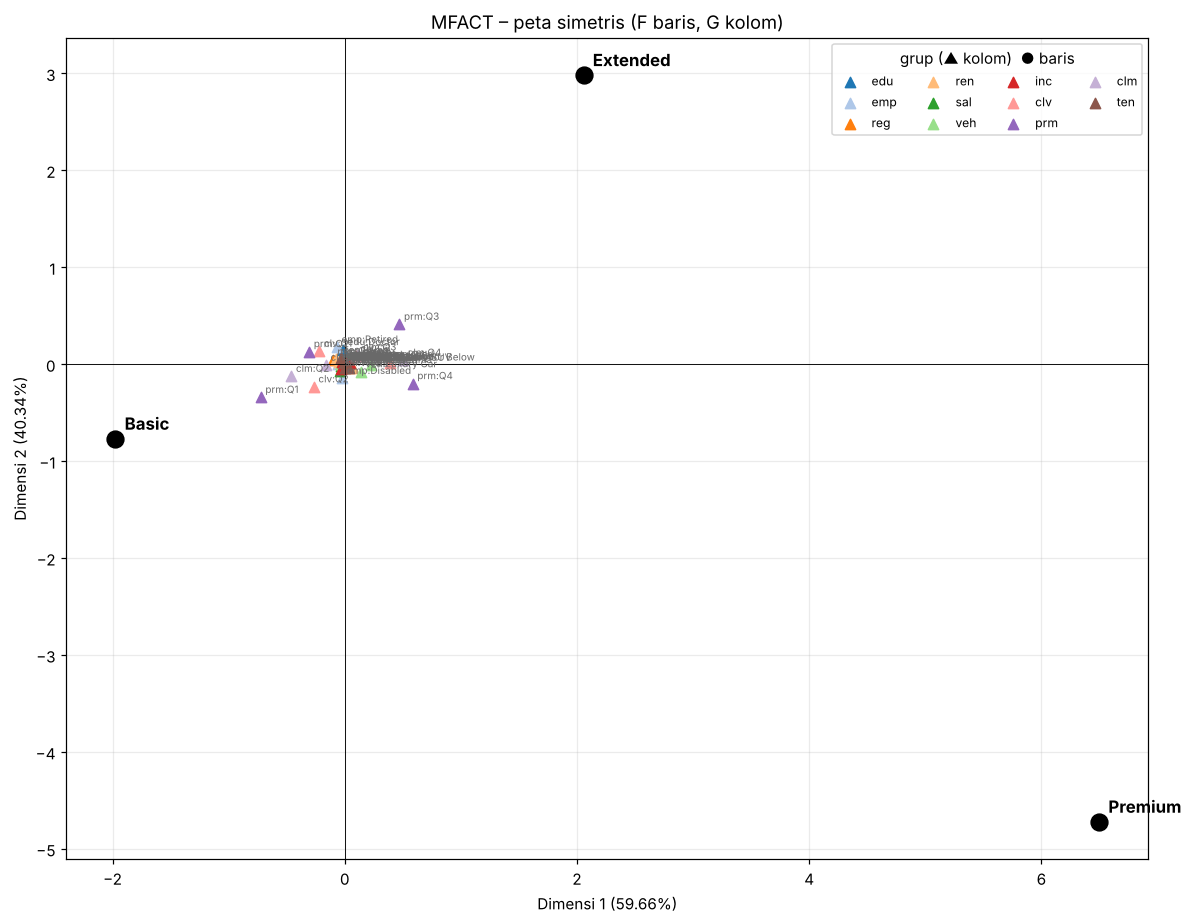

In [10]:
COL = plt.cm.tab20(np.linspace(0, 1, 20))[::2][:len(VARS_ALL)] if len(VARS_ALL) <= 10 else plt.cm.tab20(np.arange(11) / 20)
gcolor = {v: plt.cm.tab20(i/20) for i, v in enumerate(VARS_ALL)}
labs = [f'{SHORT[g]}:{shortcat(c)}' for g, c in Kt.columns]

def pct_label(M, d): return f'Dimensi {d+1} ({M["pct"][d]:.2f}%)'

def peta_baris_kolom(M, kolom, judul, alpha=1.0):
    fig, ax = plt.subplots(figsize=(11, 8.5))
    for g in M['vars']:
        m = M['grp'] == g
        ax.scatter(kolom[m, 0], kolom[m, 1], color=gcolor[g], marker='^', s=45, label=SHORT[g])
    for j, t in enumerate(labs): ax.annotate(t, kolom[j, :2], fontsize=6.5, xytext=(3, 3), textcoords='offset points', color='dimgray')
    ax.scatter(M['F'][:, 0], M['F'][:, 1], c='black', s=120, marker='o', zorder=5)
    for i, t in enumerate(M['rows']): ax.annotate(t, M['F'][i, :2], fontsize=11, fontweight='bold', xytext=(6, 6), textcoords='offset points')
    ax.axhline(0, c='k', lw=.6); ax.axvline(0, c='k', lw=.6)
    ax.set_xlabel(pct_label(M, 0)); ax.set_ylabel(pct_label(M, 1)); ax.set_title(judul)
    ax.legend(ncol=4, fontsize=8, title='grup (▲ kolom)  ● baris', loc='best')
    plt.tight_layout(); plt.show()

# (a) Peta simetris: baris F dan kolom G (keduanya koordinat utama)
peta_baris_kolom(M, M['G'], 'MFACT – peta simetris (F baris, G kolom)')

alpha_RMS = 57.4069 | alpha_mean = 80.3424  (koordinat kolom standar dikali alpha; hubungan antar titik tidak berubah)


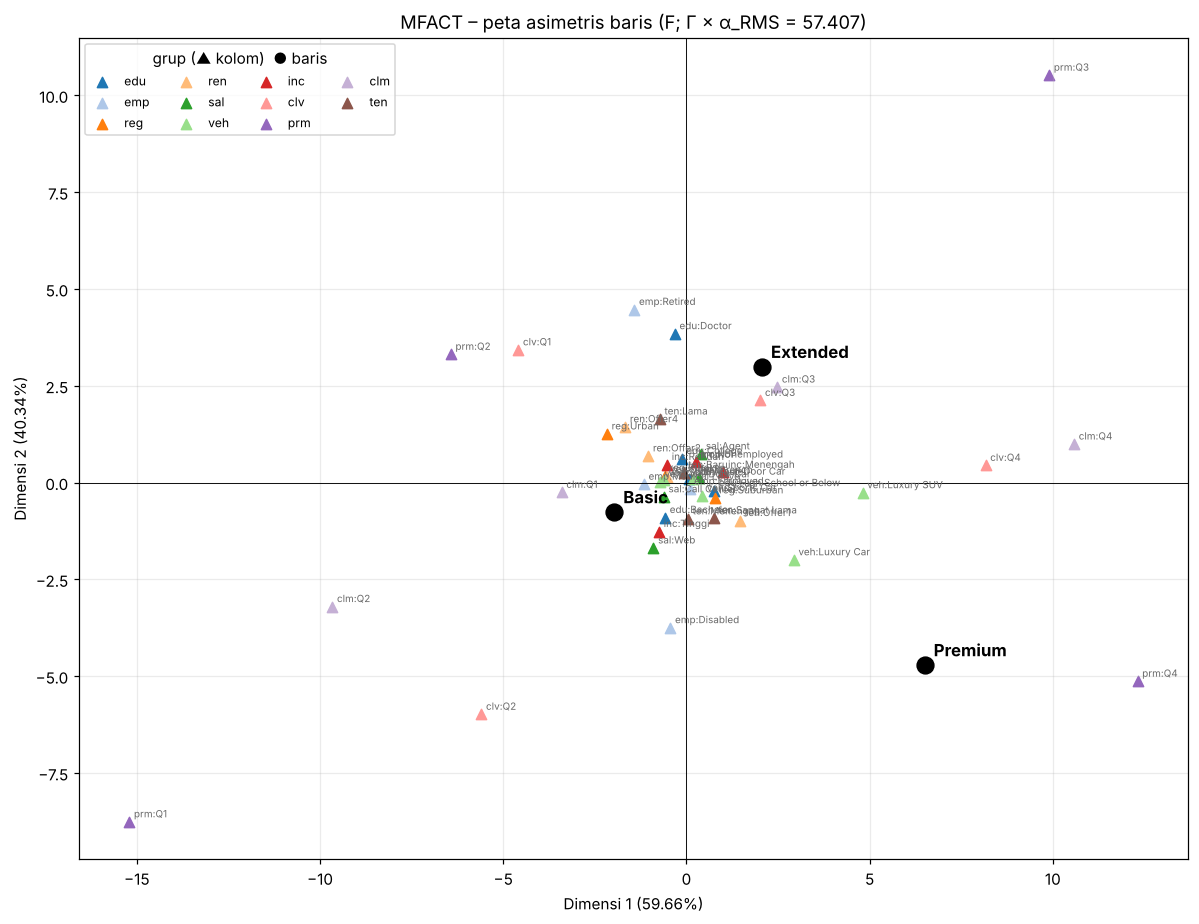

In [11]:
# (b) Peta asimetris baris: baris F (utama), kolom Gamma (standar) dikali konstanta skala alpha (RMS) agar terbaca
Fm, Gm = M['F'][:, :2], M['Gamma'][:, :2]
rms_row = np.sqrt((np.linalg.norm(Fm, axis=1)**2).mean()); rms_col = np.sqrt((np.linalg.norm(Gm, axis=1)**2).mean())
alpha_rms = rms_row / rms_col
alpha_mean = np.linalg.norm(Fm, axis=1).mean() / np.linalg.norm(Gm, axis=1).mean()
print(f'alpha_RMS = {alpha_rms:.4f} | alpha_mean = {alpha_mean:.4f}  (koordinat kolom standar dikali alpha; hubungan antar titik tidak berubah)')
peta_baris_kolom(M, M['Gamma'] * alpha_rms, f'MFACT – peta asimetris baris (F; Γ × α_RMS = {alpha_rms:.3f})')

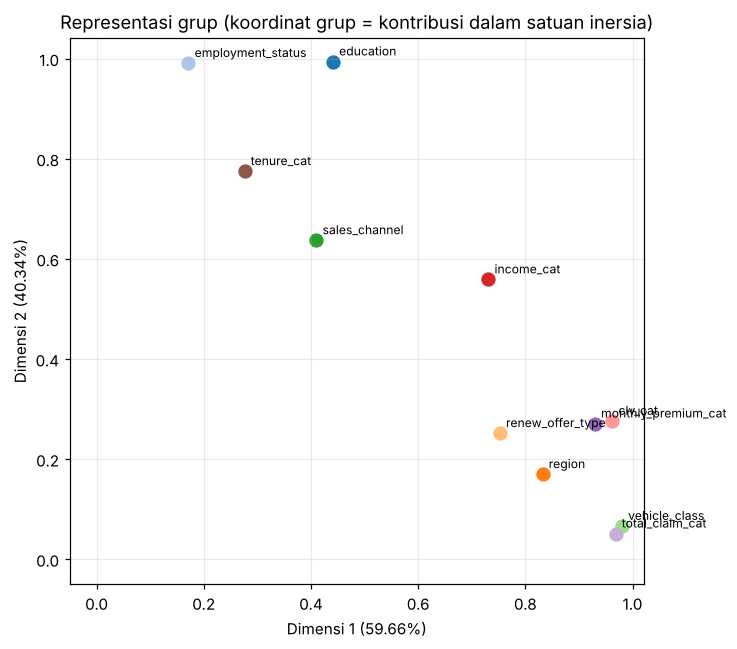

In [12]:
# (c) Representasi grup
fig, ax = plt.subplots(figsize=(6.8, 6))
for i, g in enumerate(M['vars']):
    ax.scatter(M['GC'][i, 0], M['GC'][i, 1], color=gcolor[g], s=70)
    ax.annotate(g, (M['GC'][i, 0], M['GC'][i, 1]), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax.set_xlabel(f'Dimensi 1 ({M["pct"][0]:.2f}%)'); ax.set_ylabel(f'Dimensi 2 ({M["pct"][1]:.2f}%)')
ax.set_title('Representasi grup (koordinat grup = kontribusi dalam satuan inersia)')
ax.set_xlim(left=-0.05); ax.set_ylim(bottom=-0.05); plt.tight_layout(); plt.show()

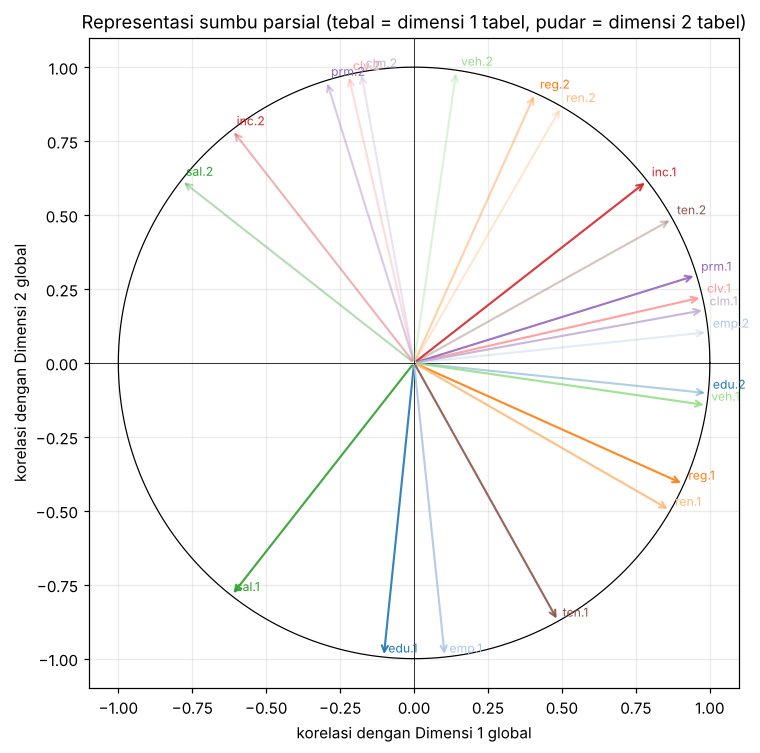

In [13]:
# (d) Sumbu parsial: lingkaran korelasi
fig, ax = plt.subplots(figsize=(7, 7)); th = np.linspace(0, 2*np.pi, 300)
ax.plot(np.cos(th), np.sin(th), 'k', lw=.8)
for _, row in M['pa'].iterrows():
    c = gcolor[row['grup']]; x, y = row['korelasi Dim1'], row['korelasi Dim2']
    ax.annotate('', (x, y), (0, 0), arrowprops=dict(arrowstyle='->', color=c, lw=1.4, alpha=.9 if row['dim_tabel']==1 else .35))
    ax.annotate(f'{SHORT[row["grup"]]}.{int(row["dim_tabel"])}', (x, y), fontsize=8, color=c, xytext=(3, 3), textcoords='offset points')
ax.axhline(0, c='k', lw=.5); ax.axvline(0, c='k', lw=.5); ax.set_aspect('equal')
ax.set_xlabel('korelasi dengan Dimensi 1 global'); ax.set_ylabel('korelasi dengan Dimensi 2 global')
ax.set_title('Representasi sumbu parsial (tebal = dimensi 1 tabel, pudar = dimensi 2 tabel)')
plt.tight_layout(); plt.show()

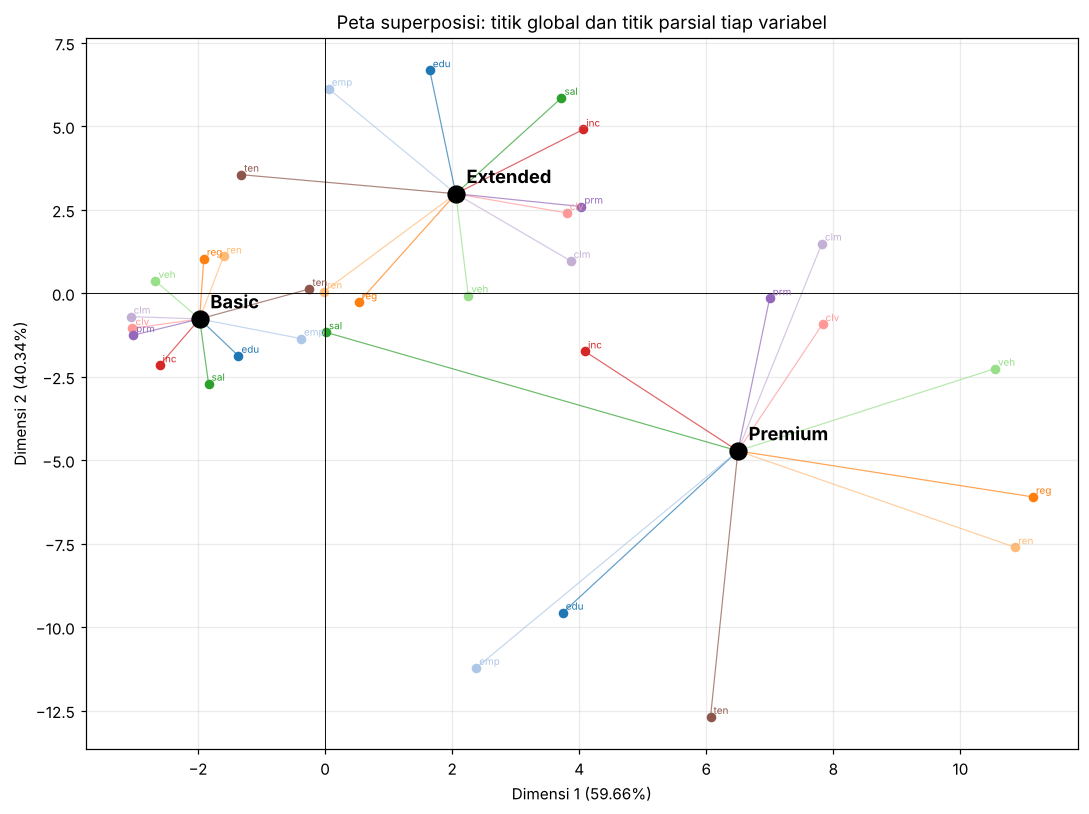

In [14]:
# (e) Superposisi: titik global (hitam) dan titik parsial tiap grup (berwarna)
fig, ax = plt.subplots(figsize=(10, 7.5))
for i, rname in enumerate(M['rows']):
    for g in M['vars']:
        p = M['Fpart'][g][i]
        ax.plot([M['F'][i, 0], p[0]], [M['F'][i, 1], p[1]], color=gcolor[g], lw=.8, alpha=.7)
        ax.scatter(p[0], p[1], color=gcolor[g], s=28)
        ax.annotate(SHORT[g], p[:2], fontsize=6.5, xytext=(2, 2), textcoords='offset points', color=gcolor[g])
    ax.scatter(M['F'][i, 0], M['F'][i, 1], c='black', s=120, zorder=5)
    ax.annotate(rname, M['F'][i, :2], fontsize=12, fontweight='bold', xytext=(7, 7), textcoords='offset points')
ax.axhline(0, c='k', lw=.6); ax.axvline(0, c='k', lw=.6)
ax.set_xlabel(pct_label(M, 0)); ax.set_ylabel(pct_label(M, 1))
ax.set_title('Peta superposisi: titik global dan titik parsial tiap variabel')
plt.tight_layout(); plt.show()

## Langkah 9: Uji sensitivitas
Pembobotan 1/λ₁ᵗ menyetarakan semua grup, sehingga variabel yang sangat lemah ikut diperkuat. Tiga skenario dibandingkan:

| Kode | Variabel | Tujuan |
|---|---|---|
| **S11** | semua 11 variabel | acuan |
| **S9** | tanpa `income_cat` dan `sales_channel` (asosiasi hampir nol) | apakah dua variabel terlemah mengganggu? |
| **S8** | tanpa `monthly_premium_cat`, `total_claim_cat`, `clv_cat` | apakah variabel "nilai" (yang mungkin ikut ditentukan oleh jenis polis) mendominasi? |

In [15]:
SCEN = {'S11': VARS_ALL,
        'S9':  [v for v in VARS_ALL if v not in ('income_cat', 'sales_channel')],
        'S8':  [v for v in VARS_ALL if v not in ('monthly_premium_cat', 'total_claim_cat', 'clv_cat')]}
RES = {k: (M if k == 'S11' else mfact_core(v)) for k, v in SCEN.items()}

rows_cmp = []
for k, R in RES.items():
    rows_cmp.append(dict(skenario=k, T=R['T'], J=R['J'], lambda1=R['lam'][0], lambda2=R['lam'][1], pct_dim1=R['pct'][0], pct_dim2=R['pct'][1],
                         total_inersia=R['lam'].sum(), **{f'F[{n}] D1': R['F'][i, 0] for i, n in enumerate(R['rows'])},
                         **{f'F[{n}] D2': R['F'][i, 1] for i, n in enumerate(R['rows'])}))
display(pd.DataFrame(rows_cmp).set_index('skenario').T)

display(Markdown('**Kontribusi grup (%) per skenario**'))
gc = pd.concat({k: pd.DataFrame(R['GCpct'], R['vars'], ['Dim1 %', 'Dim2 %']) for k, R in RES.items()}, axis=1)
display(gc)

display(Markdown('**Korelasi koordinat baris dan kolom skenario lain terhadap S11** (tanda sumbu sudah dijangkar)'))
base = RES['S11']; out = []
for k in ('S9', 'S8'):
    R = RES[k]
    common = [c for c in R['Kt'].columns if c in set(base['Kt'].columns)]
    ib = [list(base['Kt'].columns).index(c) for c in common]; ir = [list(R['Kt'].columns).index(c) for c in common]
    out.append(dict(skenario=k,
                    **{f'baris D{d+1}': np.corrcoef(base['F'][:, d], R['F'][:, d])[0, 1] for d in range(2)},
                    **{f'kolom D{d+1} ({len(common)} kategori)': np.corrcoef(base['G'][ib, d], R['G'][ir, d])[0, 1] for d in range(2)}))
display(pd.DataFrame(out).set_index('skenario'))

/tmp/ipykernel_151/1900405586.py:68: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  pa['panjang vektor'] = np.sqrt((pa[[f'korelasi Dim{d+1}' for d in range(K)]]**2).sum(1))
/tmp/ipykernel_151/1900405586.py:68: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  pa['panjang vektor'] = np.sqrt((pa[[f'korelasi Dim{d+1}' for d in range(K)]]**2).sum(1))


skenario,S11,S9,S8
T,11.0000,9.0000,8.0000
J,47.0000,39.0000,35.0000
lambda1,7.4558,6.5550,5.0885
lambda2,5.0416,3.6053,3.9500
pct_dim1,59.6588,64.5160,56.2976
pct_dim2,40.3412,35.4840,43.7024
total_inersia,12.4973,10.1603,9.0385
F[Basic] D1,-1.9746,-1.5238,-0.7189
F[Extended] D1,2.0571,0.8777,-0.6930
F[Premium] D1,6.4976,7.3762,7.1635


**Kontribusi grup (%) per skenario**

S11              S9              S8        
                     Dim1 %  Dim2 %  Dim1 %  Dim2 %  Dim1 %  Dim2 %
education            5.9158 19.7170  6.9350 27.1970 12.2547 20.5451
employment_status    2.2995 19.6552  4.3584 24.3167 12.0374 13.9204
region              11.1621  3.3660 14.9882  0.5394 17.9818  2.2006
renew_offer_type    10.0935  4.9916 14.4504  1.5804 18.9046  1.0695
sales_channel        5.5015 12.6349     NaN     NaN  0.9805 25.2475
vehicle_class       13.1503  1.3161 14.9483  1.8569 14.1136  8.3199
income_cat           9.8053 11.0841     NaN     NaN  6.1907 24.6796
clv_cat             12.9083  5.4797 12.4517 11.7181     NaN     NaN
monthly_premium_cat 12.4708  5.3718 11.4757 12.4367     NaN     NaN
total_claim_cat     12.9897  1.0127 12.1897  6.1161     NaN     NaN
tenure_cat           3.7032 15.3707  8.2026 14.2388 17.5366  4.0173

**Korelasi koordinat baris dan kolom skenario lain terhadap S11** (tanda sumbu sudah dijangkar)

,baris D1,baris D2,kolom D1 (39 kategori),kolom D2 (39 kategori),kolom D1 (35 kategori),kolom D2 (35 kategori)
skenario,,,,,,
S9,0.9732,0.9664,0.9888,0.9122,NaN,NaN
S8,0.8810,0.6529,NaN,NaN,0.8506,0.6228


## Langkah 10: Ekspor koordinat kolom untuk klasterisasi
Tabel di bawah (47 kategori × 2 dimensi, skenario S11) adalah masukan untuk k-means dan spectral clustering. Koordinat utama **G** dipakai karena jarak antar-titik pada G mencerminkan kemiripan pola antar kategori terhadap `coverage`.

In [16]:
COORD_COL = pd.DataFrame({'grup': [g for g, _ in Kt.columns], 'kategori': [c for _, c in Kt.columns],
                          'massa': M['pc'], 'Dim1': M['G'][:, 0], 'Dim2': M['G'][:, 1]})
COORD_COL.to_csv('mfact_koordinat_kolom.csv', index=False)
print('Tersimpan: mfact_koordinat_kolom.csv', COORD_COL.shape)
COORD_COL.head(10)

Tersimpan: mfact_koordinat_kolom.csv (47, 5)


,grup,kategori,massa,Dim1,Dim2
0,education,High School or Below,0.0261,0.0362,-0.0082
1,education,College,0.0267,-0.0061,0.0242
2,education,Bachelor,0.0274,-0.0277,-0.0354
3,education,Master,0.0074,0.0037,0.0031
4,education,Doctor,0.0034,-0.0150,0.1503
5,employment_status,Disabled,0.0040,-0.0208,-0.1467
6,employment_status,Employed,0.0567,0.0041,-0.0065
7,employment_status,Medical Leave,0.0043,-0.0551,-0.0017
8,employment_status,Retired,0.0028,-0.0675,0.1748
9,employment_status,Unemployed,0.0231,0.0122,0.0206
